# 04 · One-stage anchor-free detector: YOLOv8

YOLOv8 (Ultralytics) predicts, at every location of the stride-8/16/32 grids, the distances from that location to the four box edges (as discrete distributions, DFL) plus class scores; there are no anchor boxes. Positives are chosen by the **Task-Aligned Assigner** (TOOD): among grid points whose centre lies inside a GT box, the top-k by `score^α · IoU^β` become positives.

Protocol: same frames, `imgsz`, epochs and evaluator as notebooks 02–03. Augmentation is reduced to horizontal flip (`ultra.PROTOCOL_AUG`) so that the comparison is about the model, not the augmentation.

Experiments: **Y0** yolov8s → **Y1** + P2 (stride-4) head → **Y2** input-resolution search {1024, 1280, 1536} on the better architecture → **Y3** label assignment (TAL top-k 10 → 13).

## 1. Setup, protocol and dataset export

In [1]:
import os, sys, json, shutil
from pathlib import Path

REPO = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path("..").resolve()
if Path("/kaggle").exists() and not REPO.exists():
    !git clone https://github.com/dd8ria/ai-hw2.git {REPO}
    !pip install -q faster-coco-eval ultralytics==8.3.*
sys.path.insert(0, str(REPO / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as patches, cv2
import vdet, parallel, ultra
from vdet import CLASSES

vdet.seed_everything()
ROOT = vdet.find_data_root()
OUT = Path("/kaggle/working") if Path("/kaggle").exists() else REPO / "outputs"
RUNS = OUT / "runs"; RUNS.mkdir(parents=True, exist_ok=True)
RESULT_DIRS = [RUNS, REPO / "results"]   # own runs + runs committed by the teammate
P = vdet.PROTOCOL

# restore finished runs from earlier versions of this notebook (attached as Kaggle input)
for src in (Path("/kaggle/input").glob("*/runs/*") if Path("/kaggle/input").exists() else []):
    if (src / "config.json").exists() and not (RUNS / src.name).exists():
        shutil.copytree(src, RUNS / src.name); print("restored", src.name)

Cloning into '/kaggle/working/repo'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 50 (delta 11), reused 23 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 4.38 MiB | 12.95 MiB/s, done.
Resolving deltas: 100% (11/11), done.


In [2]:
imgs, anns = vdet.load_all(ROOT)
folds = pd.read_csv(OUT / "folds.csv") if (OUT / "folds.csv").exists() else vdet.make_folds(imgs, P["n_folds"])
folds.to_csv(OUT / "folds.csv", index=False)   # the parallel runner reads the split from this file
train_frames, val_frames = vdet.protocol_frames(imgs, folds, P)
train_gt = anns[anns.key.isin(train_frames.key) & (anns.iscrowd == 0)]
print(json.dumps(P))
print(f"train: {len(train_frames)} frames | val: {len(val_frames)} frames / {val_frames.clip_uid.nunique()} clips")

# Ultralytics needs files on disk: symlinks + masked copies of frames with ignored regions
data_yaml = vdet.build_yolo_dataset(imgs, anns, folds, val_fold=P["val_fold"], out_dir=OUT / "yolo_fold0",
                                    step=P["step"], val_step=P["val_step"], mask_ignore=True)

{"val_fold": 0, "n_folds": 5, "step": 10, "val_step": 10, "imgsz": 1280, "epochs": 12, "seed": 42}
train: 2189 frames | val: 545 frames / 12 clips
train:   2189 frames,  1570 masked copies
val  :    545 frames,   409 masked copies


## 2. How locations are assigned without anchors — and what it means for tiny objects

A box can only get positives from grid points whose centre falls inside it. The table counts how many such points a training box has on each stride (boxes rescaled to `imgsz`).

In [3]:
sc = (P["imgsz"] / np.maximum(train_gt.width, train_gt.height)).values
w, h = train_gt.w.values * sc, train_gt.h.values * sc
rows = []
for s in [4, 8, 16, 32]:
    pts = np.floor(w / s) * np.floor(h / s)  # lower bound on points inside the box
    rows.append({"stride": s, "median points": np.median(pts), "share with 0 points": (pts == 0).mean(),
                 "share with <4 points": (pts < 4).mean()})
display(pd.DataFrame(rows).style.format("{:.3f}", subset=["share with 0 points", "share with <4 points"]))

,stride,median points,share with 0 points,share with <4 points
0,4,49.000000,0.000,0.008
1,8,10.000000,0.012,0.185
2,16,2.000000,0.218,0.675
3,32,0.000000,0.703,0.944


If many boxes have zero or one point even on stride 8, the assigner cannot pick its top-k candidates for them, and in dense scenes neighbouring boxes compete for the same points. A stride-4 P2 head (Y1) quadruples the number of candidate points per box; higher resolution (Y2) has a similar effect on every level, at a quadratic compute cost.

## 3. Experiments

In [4]:
BASE = dict(model="yolov8s.pt", imgsz=P["imgsz"], epochs=P["epochs"], batch=8, seed=P["seed"])
EXPERIMENTS = {
    "yolo_y0_base": BASE,
    "yolo_y1_p2": {**BASE, "model": "yolov8s-p2.yaml", "weights": "yolov8s.pt"},
}
ARCH = "yolo_y1_p2"    # set to the better of y0/y1 before running Y2/Y3
for s in [1024, 1536]:
    EXPERIMENTS[f"yolo_y2_imgsz{s}"] = {**EXPERIMENTS[ARCH], "imgsz": s, "batch": 8 if s <= 1280 else 4}
EXPERIMENTS["yolo_y3_tal13"] = {**EXPERIMENTS[ARCH], "tal_topk": 13}
pd.DataFrame(EXPERIMENTS).T

,model,imgsz,epochs,batch,seed,weights,tal_topk
yolo_y0_base,yolov8s.pt,1280,12,8,42,NaN,NaN
yolo_y1_p2,yolov8s-p2.yaml,1280,12,8,42,yolov8s.pt,NaN
yolo_y2_imgsz1024,yolov8s-p2.yaml,1024,12,8,42,yolov8s.pt,NaN
yolo_y2_imgsz1536,yolov8s-p2.yaml,1536,12,4,42,yolov8s.pt,NaN
yolo_y3_tal13,yolov8s-p2.yaml,1280,12,8,42,yolov8s.pt,13


In [5]:
# Accelerator "GPU T4 x2": two runs train at the same time, one per GPU (quota is per session hour).
# Queue as many runs as fit into the 12 h session; finished runs are skipped. Logs: runs/<name>.log
RUN = ["yolo_y0_base", "yolo_y1_p2", "yolo_y2_imgsz1024", "yolo_y2_imgsz1536", "yolo_y3_tal13"]
codes = parallel.run_parallel([(n, EXPERIMENTS[n]) for n in RUN], RUNS, folds_csv=OUT / "folds.csv", data_yaml=data_yaml)

5 jobs on GPUs [0, 1]
[   0.0 min] started yolo_y0_base on GPU 0
[   0.0 min] started yolo_y1_p2 on GPU 1
[   0.5 min] yolo_y0_base (GPU 0): Downloading https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11n.pt to 'yolo11n.pt': 100% ━━━━━━━━━━━━ 5.4MB 190.8MB/s 0.0s
[   0.5 min] yolo_y1_p2 (GPU 1): AMP: running Automatic Mixed Precision (AMP) checks...
[  10.5 min] yolo_y0_base (GPU 0):        4/12       8.9G      1.395     0.8266      1.054        347       1280: 81% ━━━━━━━━━╸── 223/274 1.9it/s 1:55<26.5s
[  10.5 min] yolo_y1_p2 (GPU 1):        1/12      13.4G      3.727      4.804      4.368        272       1280: 22% ━━╸───────── 59/274 1.1s/it 9:26<3:59WARNING ⚠️ CUDA OutOfMemoryError in TaskAlignedAssigner, using CPU
[  20.5 min] yolo_y0_base (GPU 0):        8/12       8.5G      1.201     0.6446     0.9862        385       1280: 72% ━━━━━━━━╸─── 197/274 1.9it/s 1:42<40.1s
[  20.5 min] yolo_y1_p2 (GPU 1):        1/12      13.4G       3.25      3.858      4.076     

**Search range and selection.** Architecture: {P3–P5, P2–P5}. Resolution: {1024, 1280, 1536} (above 1536 the batch no longer fits a T4 at a useful size). Label assignment: TAL top-k ∈ {10, 13}. Each choice is made on the fold-0 holdout before moving to the next.

## 4. Results by object size, against the tuned anchor-based detectors

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_max,ms_per_img,epochs
run,,,,,,,,,
yolo_y0_base,0.2028,0.3653,0.1958,0.0959,0.1533,0.3495,0.3058,23.3,12
yolo_y1_p2,0.1990,0.3794,0.1836,0.0810,0.1603,0.3504,0.3183,26.3,12
yolo_y2_imgsz1024,0.1719,0.3332,0.1569,0.0705,0.1285,0.3184,0.2798,19.9,12
yolo_y2_imgsz1536,0.2097,0.4052,0.1939,0.0926,0.1766,0.3248,0.3199,30.5,12
yolo_y3_tal13,0.1937,0.3754,0.1712,0.0883,0.1515,0.3391,0.3267,21.0,12


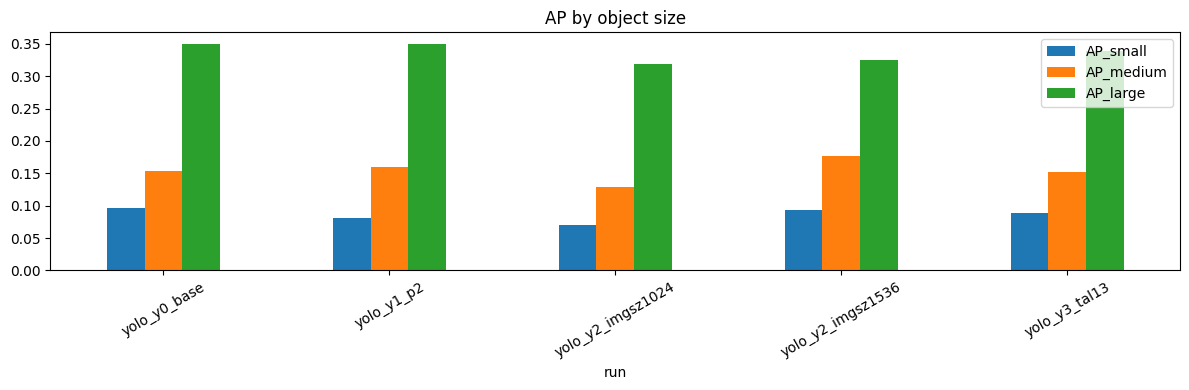

In [6]:
COLS = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_max", "ms_per_img", "epochs"]
def show(res, cols=COLS):
    cols = [c for c in cols if c in res]
    num = [c for c in cols if c not in ("ms_per_img", "epochs")]
    return res[cols].style.format("{:.4f}", subset=num).format("{:.1f}", subset=[c for c in ["ms_per_img"] if c in cols])

res = vdet.collect_results(RESULT_DIRS, "yolo")
others = [vdet.collect_results(RESULT_DIRS, p) for p in ("frcnn", "retina")]
for o in others:
    if len(o): res = pd.concat([res, o.loc[[o.AP.idxmax()]]])
if len(res):
    display(show(res))
    res[["AP_small", "AP_medium", "AP_large"]].plot.bar(figsize=(12, 4), rot=30, title="AP by object size")
    plt.tight_layout(); plt.savefig(OUT / "ap_by_size_anchor_free.png", dpi=120); plt.show()

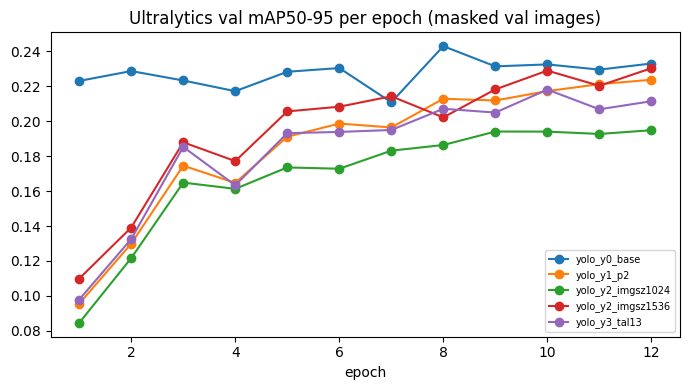

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for run in [r for r in res.index if r.startswith("yolo")] if len(res) else []:
    h = vdet.load_history(RESULT_DIRS, run)
    if h is not None: ax.plot(h.epoch, h.AP_ultra, "o-", label=run)
ax.set_title("Ultralytics val mAP50-95 per epoch (masked val images)"); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

Note: per-epoch curves come from the Ultralytics validator on the exported (masked) val images; the tables use our evaluator on the original frames, as for every other model.

## 5. Export and test submission

In [8]:
BEST = res.drop(index=[i for i in res.index if not i.startswith("yolo")]).AP.idxmax() if len(res) else "yolo_y0_base"
model = ultra.load(RUNS / BEST); imgsz = json.loads((RUNS / BEST / "config.json").read_text())["imgsz"]
test_preds = ultra.predict_test(model, ROOT, imgsz)
test_preds.to_csv(OUT / f"test_preds_{BEST}.csv.gz", index=False)
vdet.write_submission(test_preds, ROOT / "test_images.csv", OUT / f"submission_{BEST}.csv")

submission OK: 3811 rows, 3811 non-empty


,image_id,PredictionString
0,clip_001_0000001,0 0.9150 723.8 898.8 65.0 175.0 0 0.8799 972.5...
1,clip_001_0000002,0 0.8984 972.5 714.4 40.0 103.8 0 0.8872 1218....
2,clip_001_0000003,0 0.9160 712.5 905.0 67.5 175.0 0 0.8975 612.5...
3,clip_001_0000004,0 0.9307 702.5 911.2 62.5 167.5 0 0.9204 868.8...
4,clip_001_0000005,0 0.9360 672.5 925.0 67.5 155.0 0 0.8955 725.0...
...,...,...
3806,clip_048_0000041,2 0.9209 796.9 259.4 44.3 50.5 2 0.8965 981.0 ...
3807,clip_048_0000042,2 0.9458 797.8 253.7 44.3 47.8 2 0.9292 311.7 ...
3808,clip_048_0000043,2 0.9448 797.3 252.3 44.3 47.8 2 0.9277 772.1 ...
3809,clip_048_0000044,2 0.9551 795.1 247.0 44.3 48.7 2 0.9365 773.0 ...


In [9]:
# Results for the repo: unzip results.zip from the notebook Output into <repo>/results/ and commit.
vdet.export_results(RUNS, OUT / "results", preds_for=(BEST,))

results archive: /kaggle/working/results.zip


PosixPath('/kaggle/working/results.zip')